# SCIN Skin Condition Classification — Baseline Training & Testing

**Independent SCIN-only notebook.** This notebook uses the Google Research SCIN dataset and its own case metadata, dermatologist labels, and image paths. It does not use the DermNet dataset, the previous 23-class experiment, or any results from that project.

**Scope:** image-only, single-label baseline classifier. No additional novelty module is included here. The notebook converts each case's `weighted_skin_condition_label` differential into its highest-weight condition for a clearly defined baseline task. Cases without usable condition labels are excluded. All images belonging to a case stay in the same split to reduce case-level leakage.

Run in Google Colab with access to the public SCIN Cloud Storage bucket. Model metrics will be generated only after you run the notebook; no accuracy is assumed or pre-filled.

## 1. Install packages and import libraries

In [ ]:
!pip -q install google-cloud-storage scikit-learn seaborn

import os, ast, json, random, hashlib, io, math
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, balanced_accuracy_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Authenticate and configure SCIN storage

The official SCIN demo notebook uses project `dx-scin-public`, bucket `dx-scin-public-data`, and these CSV paths. In Colab, authenticate with the Google account prompt. If you run outside Colab, authenticate with the Google Cloud SDK instead.

In [ ]:
try:
    from google.colab import auth
    auth.authenticate_user()
except ImportError:
    print("Not running in Colab. Ensure Application Default Credentials are configured.")

from google.cloud import storage

GCP_PROJECT = "dx-scin-public"
BUCKET_NAME = "dx-scin-public-data"
CASES_CSV = "dataset/scin_cases.csv"
LABELS_CSV = "dataset/scin_labels.csv"
IMAGE_DIR = "dataset/images"

storage_client = storage.Client(project=GCP_PROJECT)
bucket = storage_client.bucket(BUCKET_NAME)

def read_gcs_csv(blob_path):
    blob = bucket.blob(blob_path)
    if not blob.exists():
        raise FileNotFoundError(f"Missing object in SCIN bucket: {blob_path}")
    return pd.read_csv(io.BytesIO(blob.download_as_bytes()), dtype={"case_id": str})

cases = read_gcs_csv(CASES_CSV)
labels = read_gcs_csv(LABELS_CSV)

cases["case_id"] = cases["case_id"].astype(str)
labels["case_id"] = labels["case_id"].astype(str)
print("Cases CSV shape:", cases.shape)
print("Labels CSV shape:", labels.shape)
print("Case columns:", list(cases.columns))
print("Label columns:", list(labels.columns))

Cases CSV shape: (5033, 57)
Labels CSV shape: (5033, 17)
Case columns: ['case_id', 'source', 'release', 'year', 'age_group', 'sex_at_birth', 'fitzpatrick_skin_type', 'race_ethnicity_american_indian_or_alaska_native', 'race_ethnicity_asian', 'race_ethnicity_black_or_african_american', 'race_ethnicity_hispanic_latino_or_spanish_origin', 'race_ethnicity_middle_eastern_or_north_african', 'race_ethnicity_native_hawaiian_or_pacific_islander', 'race_ethnicity_white', 'race_ethnicity_other_race', 'race_ethnicity_prefer_not_to_answer', 'textures_raised_or_bumpy', 'textures_flat', 'textures_rough_or_flaky', 'textures_fluid_filled', 'body_parts_head_or_neck', 'body_parts_arm', 'body_parts_palm', 'body_parts_back_of_hand', 'body_parts_torso_front', 'body_parts_torso_back', 'body_parts_genitalia_or_groin', 'body_parts_buttocks', 'body_parts_leg', 'body_parts_foot_top_or_side', 'body_parts_foot_sole', 'body_parts_other', 'condition_symptoms_bothersome_appearance', 'condition_symptoms_bleeding', 'con

## 3. Merge metadata and inspect the SCIN labels

The dataset schema documents `weighted_skin_condition_label` as a dictionary of diagnosis weights. The code below parses this field safely and does not use `eval`.

In [ ]:
df = cases.merge(labels, on="case_id", how="inner", validate="one_to_one")
print("Merged cases:", len(df))

WEIGHTED_LABEL_COL = "weighted_skin_condition_label"
if WEIGHTED_LABEL_COL not in df.columns:
    raise KeyError(
        f"Expected '{WEIGHTED_LABEL_COL}' in scin_labels.csv. "
        f"Available label columns: {[c for c in df.columns if 'label' in c.lower()]}"
    )

def parse_weighted_label(value):
    if pd.isna(value):
        return None
    if isinstance(value, dict):
        parsed = value
    else:
        try:
            parsed = ast.literal_eval(str(value))
        except (ValueError, SyntaxError):
            return None
    if not isinstance(parsed, dict) or not parsed:
        return None
    cleaned = {}
    for name, weight in parsed.items():
        try:
            w = float(weight)
        except (TypeError, ValueError):
            continue
        if isinstance(name, str) and name.strip() and np.isfinite(w) and w >= 0:
            cleaned[name.strip()] = w
    return cleaned or None

df["parsed_weighted_label"] = df[WEIGHTED_LABEL_COL].apply(parse_weighted_label)
df["target_label"] = df["parsed_weighted_label"].apply(
    lambda d: max(d, key=d.get) if d else None
)
df["top_label_weight"] = df["parsed_weighted_label"].apply(
    lambda d: max(d.values()) if d else np.nan
)

print("Cases with usable weighted labels:", df["target_label"].notna().sum())
print("Cases without usable weighted labels:", df["target_label"].isna().sum())
display(df["target_label"].value_counts().head(30).to_frame("case_count"))

Merged cases: 5033
Cases with usable weighted labels: 3061
Cases without usable weighted labels: 1972


,case_count
target_label,
Eczema,488
Allergic Contact Dermatitis,270
Urticaria,214
Insect Bite,185
Folliculitis,142
Psoriasis,109
Tinea,93
Impetigo,69
Herpes Zoster,68


## 4. Define the classification cohort

This baseline uses the highest-weight dermatologist differential as the single target for each case. Because some labels are rare, `MIN_CASES_PER_CLASS` is configurable. Classes below this minimum are excluded rather than silently merged into unrelated diagnoses.

The optional `MIN_TOP_LABEL_WEIGHT` threshold is set to `0.0` by default (no confidence filtering). Increase it only if you explicitly want a stricter subset and document that choice in your report.

In [ ]:
MIN_CASES_PER_CLASS = 30
MIN_TOP_LABEL_WEIGHT = 0.0

cohort = df[df["target_label"].notna()].copy()
cohort = cohort[cohort["top_label_weight"] >= MIN_TOP_LABEL_WEIGHT].copy()

class_counts = cohort["target_label"].value_counts()
kept_classes = class_counts[class_counts >= MIN_CASES_PER_CLASS].index.tolist()
cohort = cohort[cohort["target_label"].isin(kept_classes)].copy()

if len(kept_classes) < 2:
    raise ValueError(
        "Fewer than two classes remain. Lower MIN_CASES_PER_CLASS after inspecting "
        "the class distribution, or check the SCIN label parsing."
    )

CLASS_NAMES = sorted(cohort["target_label"].unique().tolist())
class_to_index = {name: i for i, name in enumerate(CLASS_NAMES)}
cohort["label_id"] = cohort["target_label"].map(class_to_index).astype(int)

print("Cases in modelling cohort:", len(cohort))
print("Number of classes:", len(CLASS_NAMES))
display(cohort["target_label"].value_counts().to_frame("case_count"))

Cases in modelling cohort: 2140
Number of classes: 20


,case_count
target_label,
Eczema,488
Allergic Contact Dermatitis,270
Urticaria,214
Insect Bite,185
Folliculitis,142
Psoriasis,109
Tinea,93
Impetigo,69
Herpes Zoster,68


## 5. Expand case records into image records

SCIN allows up to three image paths per case. Each image inherits the case's target label, but the split is performed on `case_id` before images are expanded. This prevents images from one case appearing in both training and testing.

In [ ]:
IMAGE_PATH_COLUMNS = [c for c in ["image_1_path", "image_2_path", "image_3_path"] if c in cohort.columns]
if not IMAGE_PATH_COLUMNS:
    raise KeyError("No image_1_path / image_2_path / image_3_path columns found.")

case_table = cohort[["case_id", "target_label", "label_id"]].drop_duplicates("case_id").copy()

train_cases, temp_cases = train_test_split(
    case_table,
    test_size=0.30,
    random_state=SEED,
    stratify=case_table["label_id"]
)
val_cases, test_cases = train_test_split(
    temp_cases,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_cases["label_id"]
)

split_by_case = {}
split_by_case.update({cid: "train" for cid in train_cases["case_id"]})
split_by_case.update({cid: "validation" for cid in val_cases["case_id"]})
split_by_case.update({cid: "test" for cid in test_cases["case_id"]})

records = []
for _, row in cohort.iterrows():
    for col in IMAGE_PATH_COLUMNS:
        path = row.get(col)
        if isinstance(path, str) and path.strip():
            records.append({
                "case_id": str(row["case_id"]),
                "gcs_path": path.strip(),
                "target_label": row["target_label"],
                "label_id": int(row["label_id"]),
                "split": split_by_case[str(row["case_id"])]
            })

images_df = pd.DataFrame(records).drop_duplicates(subset=["gcs_path"])
print("Unique image paths:", len(images_df))
print(images_df["split"].value_counts())
print("Unique cases per split:")
print(images_df.groupby("split")["case_id"].nunique())

Unique image paths: 4584
split
train         3210
test           689
validation     685
Name: count, dtype: int64
Unique cases per split:
split
test           321
train         1493
validation     321
Name: case_id, dtype: int64


## 6. Download SCIN images to a local cache

Images are downloaded only when needed and cached under `/content/scin_image_cache` in Colab. Missing or unreadable image objects are logged and skipped. The SCIN README notes that one image file is missing and that a small number of duplicates are present in the release.

In [ ]:
CACHE_DIR = Path("/content/scin_image_cache")
CACHE_DIR.mkdir(parents=True, exist_ok=True)

def local_image_path(gcs_path):
    # Hash the complete object path to avoid collisions between filenames.
    suffix = Path(gcs_path).suffix.lower() or ".jpg"
    key = hashlib.sha256(gcs_path.encode("utf-8")).hexdigest()
    return CACHE_DIR / f"{key}{suffix}"

def ensure_downloaded(gcs_path):
    local_path = local_image_path(gcs_path)
    if local_path.exists() and local_path.stat().st_size > 0:
        return str(local_path)
    blob = bucket.blob(gcs_path)
    try:
        blob.download_to_filename(str(local_path))
        return str(local_path)
    except Exception as exc:
        print(f"Download skipped: {gcs_path} ({type(exc).__name__}: {exc})")
        return None

downloaded_paths = []
for gcs_path in images_df["gcs_path"].tolist():
    downloaded_paths.append(ensure_downloaded(gcs_path))

images_df["local_path"] = downloaded_paths
images_df = images_df[images_df["local_path"].notna()].copy()

def is_readable(path):
    try:
        with Image.open(path) as im:
            im.verify()
        return True
    except Exception:
        return False

readable_mask = images_df["local_path"].apply(is_readable)
print("Unreadable downloaded images:", int((~readable_mask).sum()))
images_df = images_df[readable_mask].reset_index(drop=True)

print("Usable images:", len(images_df))
print(images_df["split"].value_counts())

Download skipped: dataset/images/-2243186711511406658.png (NotFound: 404 GET https://storage.googleapis.com/download/storage/v1/b/dx-scin-public-data/o/dataset%2Fimages%2F-2243186711511406658.png?alt=media: No such object: dx-scin-public-data/dataset/images/-2243186711511406658.png: ('Request failed with status code', 404, 'Expected one of', <HTTPStatus.OK: 200>, <HTTPStatus.PARTIAL_CONTENT: 206>))
Unreadable downloaded images: 0
Usable images: 4583
split
train         3209
test           689
validation     685
Name: count, dtype: int64


## 7. Build TensorFlow input pipelines

MobileNetV2 preprocessing is applied consistently during training, validation, testing, and single-image prediction.

In [ ]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
NUM_CLASSES = len(CLASS_NAMES)

def decode_resize_preprocess(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32)
    image = preprocess_input(image)
    label = tf.one_hot(tf.cast(label, tf.int32), depth=NUM_CLASSES)
    return image, label

def make_dataset(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        frame["local_path"].astype(str).values,
        frame["label_id"].astype(np.int32).values
    ))
    if training:
        ds = ds.shuffle(min(len(frame), 5000), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(decode_resize_preprocess, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_df = images_df[images_df["split"] == "train"].copy()
val_df = images_df[images_df["split"] == "validation"].copy()
test_df = images_df[images_df["split"] == "test"].copy()

for name, frame in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    if frame.empty:
        raise ValueError(f"{name} split is empty. Check filtering and stratified splitting.")
    print(name, "images:", len(frame), "| cases:", frame["case_id"].nunique())

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

train images: 3209 | cases: 1493
validation images: 685 | cases: 321
test images: 689 | cases: 321


## 8. Visual quality check

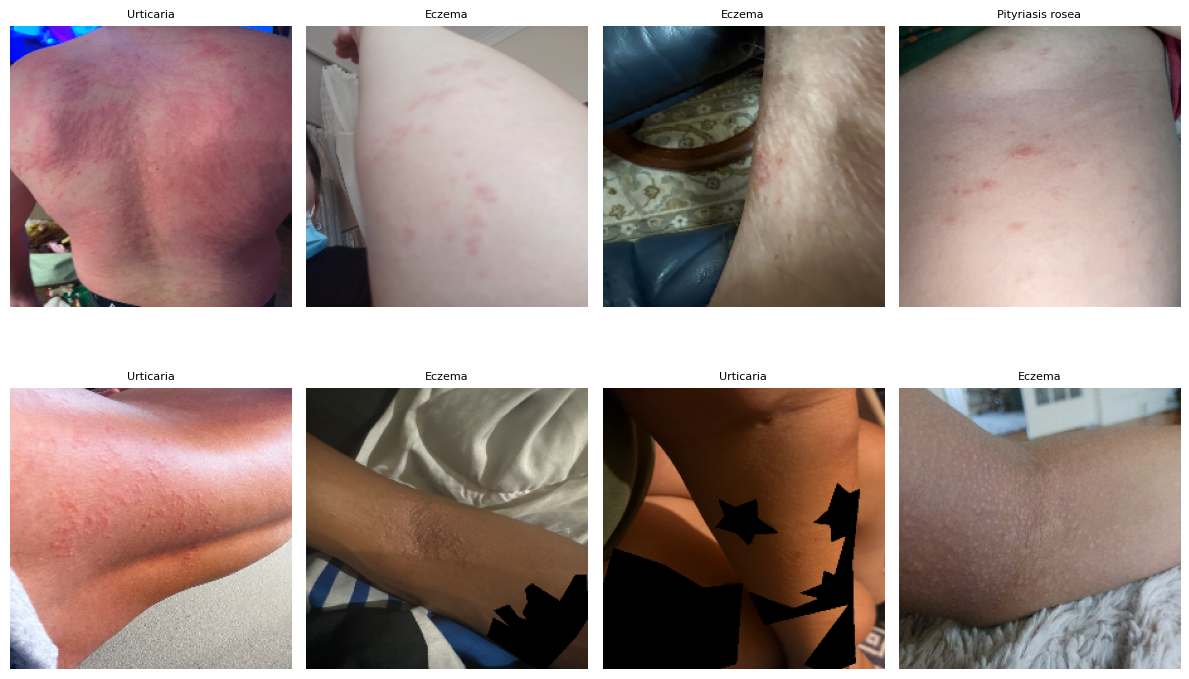

In [ ]:
plt.figure(figsize=(12, 8))
for images, labels_batch in train_ds.take(1):
    n = min(8, images.shape[0])
    for i in range(n):
        # Convert MobileNetV2 input range [-1, 1] back to display range [0, 1].
        img = (images[i].numpy() + 1.0) / 2.0
        plt.subplot(2, 4, i + 1)
        plt.imshow(np.clip(img, 0, 1))
        plt.title(CLASS_NAMES[int(np.argmax(labels_batch[i].numpy()))], fontsize=8)
        plt.axis("off")
plt.tight_layout()
plt.show()

### 10c. Pushing for High Accuracy: EfficientNetB0 + Cosine Decayed Fine-Tuning + Advanced Augmentation

To maximize the model's accuracy on the 20 classes of the SCIN dataset, we will implement an optimized pipeline:
- **Advanced Augmentation**: Introducing contrast and brightness variations.
- **EfficientNetB0**: Swapping the base architecture for a more robust feature extractor.
- **Cosine Learning Rate Decay**: Using a decaying learning rate scheduler for stable convergence.
- **Class Weighting & Strategic Layer Unfreezing**: Penalizing rare class errors while fine-tuning the base features.

In [ ]:
from tensorflow.keras.applications import EfficientNetB0

# Define advanced augmentations for medical images (texture & illumination variance)
advanced_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.20),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
    layers.RandomBrightness(0.15)
])

# Load EfficientNetB0 (note: EfficientNet handles internal rescaling, but preprocess_input is still fine or we rely on raw range)
base_efficientnet = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3)
)

# Unfreeze top blocks of EfficientNet for rich dermatological fine-tuning
base_efficientnet.trainable = True
for layer in base_efficientnet.layers[:-30]:
    layer.trainable = False

# Construct model architecture
inputs_eff = layers.Input(shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3), name="skin_image")
x_eff = advanced_augmentation(inputs_eff)
x_eff = base_efficientnet(x_eff, training=True)
x_eff = layers.GlobalAveragePooling2D()(x_eff)
x_eff = layers.BatchNormalization()(x_eff)
x_eff = layers.Dropout(0.4)(x_eff)
outputs_eff = layers.Dense(NUM_CLASSES, activation="softmax", name="condition_probabilities")(x_eff)

model_eff = models.Model(inputs_eff, outputs_eff, name="SCIN_EfficientNet_Advanced")

# Cosine Decay Learning Rate Scheduler
initial_learning_rate = 1e-4
lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=initial_learning_rate,
    decay_steps=15 * len(train_df) // BATCH_SIZE
)

model_eff.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_eff.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "SCIN_EfficientNet_Advanced"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ skin_image (InputLayer)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ condition_probabilities (Dense) │ (None, 20)             │        25,620 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,080,311 (15.57 MB)

 Trainable params: 1,524,340 (5.81 MB)

 Non-trainable params: 2,555,971 (9.75 MB)

In [ ]:
# Train the EfficientNet architecture
callbacks_eff = [
    tf.keras.callbacks.ModelCheckpoint(
        "scin_efficientnet_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    )
]

history_eff = model_eff.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=class_weights_dict,
    callbacks=callbacks_eff
)

Epoch 1/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 475ms/step - accuracy: 0.0465 - loss: 4.1193
Epoch 1: val_loss improved from None to 3.06305, saving model to scin_efficientnet_best.keras

Epoch 1: finished saving model to scin_efficientnet_best.keras
101/101 ━━━━━━━━━━━━━━━━━━━━ 81s 634ms/step - accuracy: 0.0436 - loss: 4.0074 - val_accuracy: 0.0263 - val_loss: 3.0631
Epoch 2/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 494ms/step - accuracy: 0.0471 - loss: 3.7882
Epoch 2: val_loss did not improve from 3.06305
101/101 ━━━━━━━━━━━━━━━━━━━━ 76s 601ms/step - accuracy: 0.0455 - loss: 3.7896 - val_accuracy: 0.0248 - val_loss: 3.1133
Epoch 3/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 477ms/step - accuracy: 0.0458 - loss: 3.7683
Epoch 3: val_loss did not improve from 3.06305
101/101 ━━━━━━━━━━━━━━━━━━━━ 69s 682ms/step - accuracy: 0.0414 - loss: 3.7429 - val_accuracy: 0.0175 - val_loss: 3.0935
Epoch 4/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 485ms/step - accuracy: 0.0486 - loss: 3.6850
Epoch 4: val_loss did not improve fr

In [ ]:
# Evaluate the high-capacity model on the test set
test_loss_eff, test_accuracy_eff = model_eff.evaluate(test_ds, verbose=1)
probabilities_eff = model_eff.predict(test_ds, verbose=1)
y_pred_eff = np.argmax(probabilities_eff, axis=1)

print(f"\nEfficientNet Test loss: {test_loss_eff:.4f}")
print(f"EfficientNet Test accuracy: {test_accuracy_eff:.4f}")
print(f"EfficientNet Balanced accuracy: {balanced_accuracy_score(y_true, y_pred_eff):.4f}\n")

print(classification_report(
    y_true, y_pred_eff,
    labels=np.arange(NUM_CLASSES),
    target_names=CLASS_NAMES,
    zero_division=0
))

22/22 ━━━━━━━━━━━━━━━━━━━━ 12s 559ms/step - accuracy: 0.0769 - loss: 2.9890
22/22 ━━━━━━━━━━━━━━━━━━━━ 15s 519ms/step

EfficientNet Test loss: 2.9890
EfficientNet Test accuracy: 0.0769
EfficientNet Balanced accuracy: 0.0491

                             precision    recall  f1-score   support

                       Acne       0.00      0.00      0.00        17
      Acute dermatitis, NOS       0.00      0.00      0.00        15
Allergic Contact Dermatitis       0.00      0.00      0.00        94
    CD - Contact dermatitis       0.00      0.00      0.00        15
                  Drug Rash       0.00      0.00      0.00        17
                     Eczema       0.00      0.00      0.00       165
               Folliculitis       0.00      0.00      0.00        43
             Herpes Simplex       0.00      0.00      0.00        20
              Herpes Zoster       0.00      0.00      0.00        21
                   Impetigo       0.00      0.00      0.00        23
               

### 16. Advanced Improvement: Focal Loss to combat Class Imbalance

To address the issue where the model over-predicts a single category and struggles with minority classes, we can replace `categorical_crossentropy` with **Categorical Focal Loss**. This penalizes the model more for errors on "hard" (incorrectly predicted) examples, ensuring minority classes contribute meaningfully to gradient updates.

In [ ]:
# Define Categorical Focal Loss
def categorical_focal_loss(alpha=0.25, gamma=2.0):
    def focal_loss(y_true, y_pred):
        # Clip predictions to prevent NaN/Inf values
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        # Calculate cross entropy
        cross_entropy = -y_true * tf.math.log(y_pred)
        # Calculate focal weight factor
        loss = alpha * tf.math.pow(1.0 - y_pred, gamma) * cross_entropy
        return tf.reduce_sum(loss, axis=-1)
    return focal_loss

In [ ]:
# Re-compile the EfficientNet model using the Focal Loss function
model_eff_focal = models.clone_model(model_eff)

model_eff_focal.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-5),
    loss=categorical_focal_loss(alpha=0.25, gamma=2.0),
    metrics=["accuracy"]
)

callbacks_focal = [
    tf.keras.callbacks.ModelCheckpoint(
        "scin_efficientnet_focal_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    )
]

# Train with Focal Loss
history_focal = model_eff_focal.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks_focal
)

Epoch 1/15
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 497ms/step - accuracy: 0.0814 - loss: 0.8921
Epoch 1: val_loss improved from None to 0.66804, saving model to scin_efficientnet_focal_best.keras

Epoch 1: finished saving model to scin_efficientnet_focal_best.keras
101/101 ━━━━━━━━━━━━━━━━━━━━ 78s 636ms/step - accuracy: 0.0841 - loss: 0.8578 - val_accuracy: 0.2453 - val_loss: 0.6680
Epoch 2/15
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 476ms/step - accuracy: 0.0761 - loss: 0.8375
Epoch 2: val_loss improved from 0.66804 to 0.65730, saving model to scin_efficientnet_focal_best.keras

Epoch 2: finished saving model to scin_efficientnet_focal_best.keras
101/101 ━━━━━━━━━━━━━━━━━━━━ 87s 690ms/step - accuracy: 0.0826 - loss: 0.8275 - val_accuracy: 0.2453 - val_loss: 0.6573
Epoch 3/15
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 481ms/step - accuracy: 0.0839 - loss: 0.8267
Epoch 3: val_loss improved from 0.65730 to 0.65295, saving model to scin_efficientnet_focal_best.keras

Epoch 3: finished saving model to scin_efficientn

In [ ]:
# Evaluate the Focal Loss Model
test_loss_foc, test_accuracy_foc = model_eff_focal.evaluate(test_ds, verbose=1)
y_pred_foc = np.argmax(model_eff_focal.predict(test_ds, verbose=1), axis=1)

print(f"\nFocal Loss Test accuracy: {test_accuracy_foc:.4f}")
print(f"Focal Loss Balanced accuracy: {balanced_accuracy_score(y_true, y_pred_foc):.4f}\n")

22/22 ━━━━━━━━━━━━━━━━━━━━ 10s 431ms/step - accuracy: 0.2395 - loss: 0.5871
22/22 ━━━━━━━━━━━━━━━━━━━━ 16s 508ms/step

Focal Loss Test accuracy: 0.2395
Focal Loss Balanced accuracy: 0.0500



## 9. Build the baseline image classifier

This is a conventional transfer-learning baseline using MobileNetV2 pretrained on ImageNet. The feature extractor is initially frozen; only the classification head is trained in this first stage. This is a new SCIN experiment and is not the previous VGG19/DermNet model.

In [ ]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3)
)
base_model.trainable = False

inputs = layers.Input(shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3), name="skin_image")
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.35)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="condition_probabilities")(x)

model = models.Model(inputs, outputs, name="SCIN_MobileNetV2_baseline")
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "SCIN_MobileNetV2_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ skin_image (InputLayer)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ condition_probabilities (Dense) │ (None, 20)             │        25,620 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,283,604 (8.71 MB)

 Trainable params: 25,620 (100.08 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 10. Train the classifier

In [ ]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "scin_mobilenetv2_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

EPOCHS = 20
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 654ms/step - accuracy: 0.1658 - loss: 3.0925
Epoch 1: val_loss improved from None to 2.68398, saving model to scin_mobilenetv2_best.keras

Epoch 1: finished saving model to scin_mobilenetv2_best.keras
101/101 ━━━━━━━━━━━━━━━━━━━━ 126s 977ms/step - accuracy: 0.1680 - loss: 2.9985 - val_accuracy: 0.2146 - val_loss: 2.6840 - learning_rate: 0.0010
Epoch 2/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 456ms/step - accuracy: 0.2299 - loss: 2.5643
Epoch 2: val_loss improved from 2.68398 to 2.62821, saving model to scin_mobilenetv2_best.keras

Epoch 2: finished saving model to scin_mobilenetv2_best.keras
101/101 ━━━━━━━━━━━━━━━━━━━━ 67s 667ms/step - accuracy: 0.2262 - loss: 2.5361 - val_accuracy: 0.2380 - val_loss: 2.6282 - learning_rate: 0.0010
Epoch 3/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 457ms/step - accuracy: 0.2748 - loss: 2.3107
Epoch 3: val_loss improved from 2.62821 to 2.61975, saving model to scin_mobilenetv2_best.keras

Epoch 3: finished saving model to s

### 10b. Advanced Model Improvement: Augmentation, Class Weights & Fine-tuning

To address the extreme class imbalance and overfitting identified in the baseline, we will:
1. Apply Data Augmentation.
2. Calculate and inject Balanced Class Weights.
3. Unfreeze top layers of the MobileNetV2 base for fine-tuning with a small learning rate (`1e-5`).

In [ ]:
from sklearn.utils import class_weight

# 1. Define Data Augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.1),
])

# 2. Compute Class Weights to balance the 20 classes
y_train_labels = train_df["label_id"].values
unique_classes = np.unique(y_train_labels)
computed_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=unique_classes,
    y=y_train_labels
)
class_weights_dict = dict(zip(unique_classes, computed_weights))

print("Class weights computed successfully for all classes.")
# Quick inspection of min and max class weights
print(f"Min class weight (for majority class): {min(computed_weights):.4f}")
print(f"Max class weight (for minority class): {max(computed_weights):.4f}")

Class weights computed successfully for all classes.
Min class weight (for majority class): 0.2151
Max class weight (for minority class): 3.2090


In [ ]:
# 3. Re-build model with Data Augmentation & Unfrozen Base Layers for Fine-tuning
base_model_ft = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3)
)

# Unfreeze the base model
base_model_ft.trainable = True
# Freeze all layers except the top 20 layers
for layer in base_model_ft.layers[:-20]:
    layer.trainable = False

inputs_ft = layers.Input(shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3), name="skin_image")
x_ft = data_augmentation(inputs_ft)
x_ft = base_model_ft(x_ft, training=True)
x_ft = layers.GlobalAveragePooling2D()(x_ft)
x_ft = layers.Dropout(0.4)(x_ft)
outputs_ft = layers.Dense(NUM_CLASSES, activation="softmax", name="condition_probabilities")(x_ft)

model_ft = models.Model(inputs_ft, outputs_ft, name="SCIN_MobileNetV2_FineTuned")

# Compile with a very low learning rate for fine-tuning
model_ft.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_ft.summary()

Model: "SCIN_MobileNetV2_FineTuned"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ skin_image (InputLayer)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ condition_probabilities (Dense) │ (None, 20)             │        25,620 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,283,604 (8.71 MB)

 Trainable params: 1,231,700 (4.70 MB)

 Non-trainable params: 1,051,904 (4.01 MB)

In [ ]:
# 4. Train the improved model using class weights
callbacks_ft = [
    tf.keras.callbacks.ModelCheckpoint(
        "scin_mobilenetv2_finetuned_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    )
]

# We train for 15 epochs to observe convergence under fine-tuning
history_ft = model_ft.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weights_dict,
    callbacks=callbacks_ft
)

Epoch 1/15
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 512ms/step - accuracy: 0.0361 - loss: 3.4372
Epoch 1: val_loss improved from None to 3.39628, saving model to scin_mobilenetv2_finetuned_best.keras

Epoch 1: finished saving model to scin_mobilenetv2_finetuned_best.keras
101/101 ━━━━━━━━━━━━━━━━━━━━ 85s 724ms/step - accuracy: 0.0424 - loss: 3.4372 - val_accuracy: 0.0613 - val_loss: 3.3963
Epoch 2/15
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 477ms/step - accuracy: 0.0399 - loss: 3.3054
Epoch 2: val_loss improved from 3.39628 to 3.33222, saving model to scin_mobilenetv2_finetuned_best.keras

Epoch 2: finished saving model to scin_mobilenetv2_finetuned_best.keras
101/101 ━━━━━━━━━━━━━━━━━━━━ 69s 689ms/step - accuracy: 0.0433 - loss: 3.3376 - val_accuracy: 0.0584 - val_loss: 3.3322
Epoch 3/15
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 619ms/step - accuracy: 0.0650 - loss: 3.2659
Epoch 3: val_loss improved from 3.33222 to 3.27938, saving model to scin_mobilenetv2_finetuned_best.keras

Epoch 3: finished saving model to 

In [ ]:
# 5. Evaluate the improved model on the test set
test_loss_ft, test_accuracy_ft = model_ft.evaluate(test_ds, verbose=1)
probabilities_ft = model_ft.predict(test_ds, verbose=1)
y_pred_ft = np.argmax(probabilities_ft, axis=1)

print(f"\nImproved Model Test loss: {test_loss_ft:.4f}")
print(f"Improved Model Test accuracy: {test_accuracy_ft:.4f}")
print(f"Improved Model Balanced accuracy: {balanced_accuracy_score(y_true, y_pred_ft):.4f}\n")

print(classification_report(
    y_true, y_pred_ft,
    labels=np.arange(NUM_CLASSES),
    target_names=CLASS_NAMES,
    zero_division=0
))

22/22 ━━━━━━━━━━━━━━━━━━━━ 17s 500ms/step - accuracy: 0.0595 - loss: 3.4800
22/22 ━━━━━━━━━━━━━━━━━━━━ 16s 662ms/step

Improved Model Test loss: 3.4800
Improved Model Test accuracy: 0.0595
Improved Model Balanced accuracy: 0.0511

                             precision    recall  f1-score   support

                       Acne       0.09      0.06      0.07        17
      Acute dermatitis, NOS       0.02      0.07      0.03        15
Allergic Contact Dermatitis       0.00      0.00      0.00        94
    CD - Contact dermatitis       0.02      0.20      0.04        15
                  Drug Rash       0.00      0.00      0.00        17
                     Eczema       0.50      0.01      0.01       165
               Folliculitis       0.00      0.00      0.00        43
             Herpes Simplex       0.00      0.00      0.00        20
              Herpes Zoster       0.00      0.00      0.00        21
                   Impetigo       0.00      0.00      0.00        23
         

## 11. Plot training curves

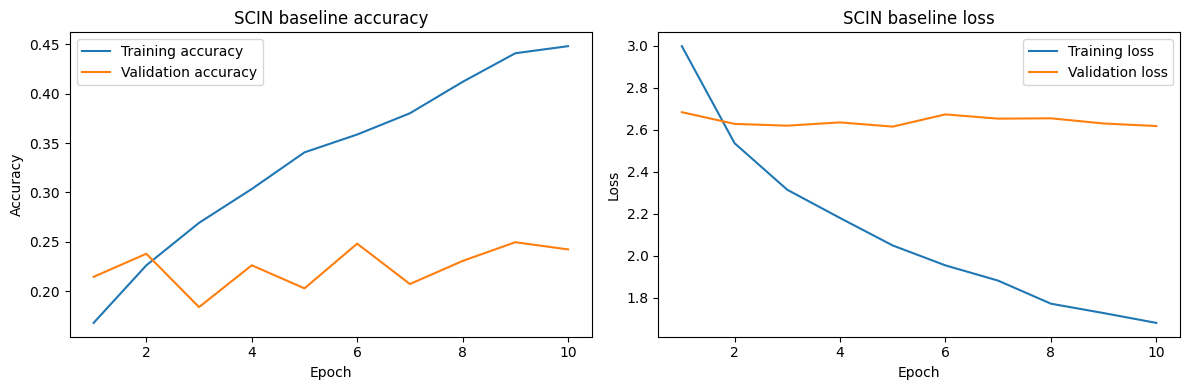

In [ ]:
hist = history.history
epochs_range = range(1, len(hist["accuracy"]) + 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, hist["accuracy"], label="Training accuracy")
plt.plot(epochs_range, hist["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("SCIN baseline accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, hist["loss"], label="Training loss")
plt.plot(epochs_range, hist["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("SCIN baseline loss")
plt.legend()
plt.tight_layout()
plt.show()

## 12. Evaluate once on the held-out test set

The test set is kept separate from model fitting and callback decisions. Report accuracy alongside macro-F1, weighted-F1, balanced accuracy, per-class precision/recall/F1, and the confusion matrix because class frequencies may differ.

In [ ]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
probabilities = model.predict(test_ds, verbose=1)
y_pred = np.argmax(probabilities, axis=1)
y_true = test_df["label_id"].to_numpy()

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_true, y_pred):.4f}")
print(classification_report(
    y_true, y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=CLASS_NAMES,
    zero_division=0
))

22/22 ━━━━━━━━━━━━━━━━━━━━ 28s 1s/step - accuracy: 0.1829 - loss: 2.6703
22/22 ━━━━━━━━━━━━━━━━━━━━ 17s 594ms/step
Test loss: 2.6703
Test accuracy: 0.1829
Balanced accuracy: 0.0885
                             precision    recall  f1-score   support

                       Acne       0.20      0.12      0.15        17
      Acute dermatitis, NOS       0.00      0.00      0.00        15
Allergic Contact Dermatitis       0.16      0.38      0.23        94
    CD - Contact dermatitis       0.00      0.00      0.00        15
                  Drug Rash       0.08      0.12      0.10        17
                     Eczema       0.28      0.31      0.30       165
               Folliculitis       0.24      0.33      0.27        43
             Herpes Simplex       0.50      0.05      0.09        20
              Herpes Zoster       0.08      0.05      0.06        21
                   Impetigo       0.00      0.00      0.00        23
                Insect Bite       0.09      0.07      0.08 

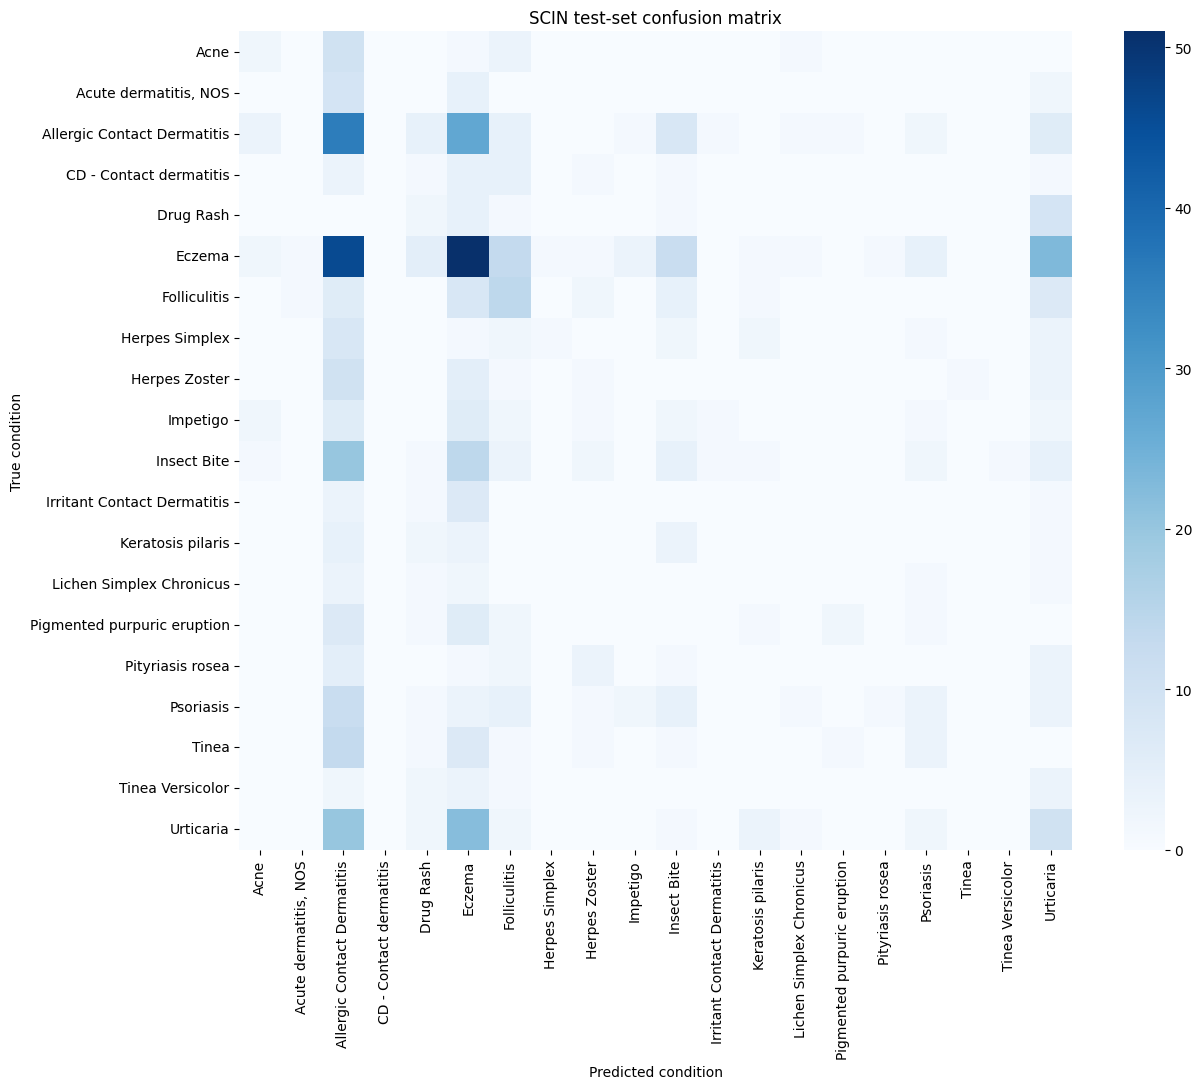

In [ ]:
cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
plt.figure(figsize=(max(10, NUM_CLASSES * 0.65), max(8, NUM_CLASSES * 0.55)))
sns.heatmap(
    cm, cmap="Blues", annot=(NUM_CLASSES <= 18), fmt="d",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES
)
plt.xlabel("Predicted condition")
plt.ylabel("True condition")
plt.title("SCIN test-set confusion matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 13. Save model, class names, and test predictions

In [ ]:
model.save("scin_skin_condition_classifier.keras")

with open("scin_class_names.json", "w") as f:
    json.dump(CLASS_NAMES, f, indent=2)

predictions_out = test_df[["case_id", "gcs_path", "target_label", "label_id"]].copy()
predictions_out["predicted_label_id"] = y_pred
predictions_out["predicted_label"] = [CLASS_NAMES[i] for i in y_pred]
predictions_out["predicted_probability"] = probabilities.max(axis=1)
predictions_out.to_csv("scin_test_predictions.csv", index=False)

print("Saved: scin_skin_condition_classifier.keras")
print("Saved: scin_class_names.json")
print("Saved: scin_test_predictions.csv")

Saved: scin_skin_condition_classifier.keras
Saved: scin_class_names.json
Saved: scin_test_predictions.csv


## 14. Predict a new image

Provide a local image path in the Colab runtime. The output is a model prediction for research/education, not a medical diagnosis.

In [ ]:
def predict_scIN_image(image_path, top_k=5):
    if not os.path.isfile(image_path):
        raise FileNotFoundError(image_path)
    with Image.open(image_path) as im:
        im = im.convert("RGB").resize(IMAGE_SIZE)
        arr = np.asarray(im, dtype=np.float32)
    arr = preprocess_input(arr)
    probs = model.predict(arr[None, ...], verbose=0)[0]
    order = np.argsort(probs)[::-1][:top_k]
    return [(CLASS_NAMES[i], float(probs[i])) for i in order]

# Example:
# predict_scIN_image("/content/example_skin_image.jpg")

## 15. Reproducibility and interpretation notes

- Dataset source: Google Research SCIN, Cloud Storage bucket `dx-scin-public-data`.
- Case metadata and dermatologist labels are joined by `case_id`.
- The target is the maximum-weight entry in `weighted_skin_condition_label`; it is a simplified single-label representation of a differential diagnosis, not the full differential.
- Cases with missing/unparseable weighted labels are excluded.
- Classes with fewer than `MIN_CASES_PER_CLASS` cases are excluded. State the chosen threshold and resulting class count in your report.
- The split is case-level, not image-level. This reduces leakage between images from the same case.
- The SCIN README reports duplicate images in the released dataset. This notebook removes exact duplicate GCS paths, but does not perform perceptual duplicate detection across different paths.
- Results depend on the actual dataset release, accessible image objects, filtering settings, hardware, and training run. Do not report metrics until this notebook has run successfully.
- SCIN is intended for health education and research. Predictions are not a substitute for clinical assessment.
- Follow the SCIN Data Use License. In particular, do not attempt to re-identify or re-link data subjects. If sharing licensed material or adaptations, follow the attribution and license conditions.